# Project 14: Product Search using Amazon ESCI
## Exploratory Data Analysis of the ESCI Sample

**Objective**: Conduct an in-depth exploratory data analysis of the official raw Amazon ESCI (Shopping Queries) dataset to understand class distributions, query patterns, and catalog characteristics prior to building our retrieval models.

### Relevance Schemes in Amazon ESCI:
- **E (Exact)**: The product is exactly what the user searched for.
- **S (Substitute)**: The product is a functional replacement/substitute.
- **C (Complement)**: The product is an accessory or complementary add-on.
- **I (Irrelevant)**: The product is completely unrelated to the query.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

# Set aesthetic styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Locate raw dataset directory
BASE_DIR = os.path.dirname(os.path.abspath('')) if '__file__' not in globals() else '.'
DATA_DIR = os.path.join(BASE_DIR, 'Amazon-ESCI', 'shopping_queries_dataset')
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join('..', 'Amazon-ESCI', 'shopping_queries_dataset')

print('Data directory located at:', os.path.abspath(DATA_DIR))
assert os.path.exists(DATA_DIR), f'Directory {DATA_DIR} does not exist!'

Data directory located at: C:\Users\rohit\Desktop\Information Retrival Project\Amazon-ESCI\shopping_queries_dataset


### 1. Raw Dataset Overview & File Schema Inspection
We inspect the two core tables:
1. `shopping_queries_dataset_examples.parquet`: Query-product pairs with ESCI judgments.
2. `shopping_queries_dataset_products.parquet`: Product catalog with titles and descriptions.

In [2]:
ex_path = os.path.join(DATA_DIR, 'shopping_queries_dataset_examples.parquet')
pr_path = os.path.join(DATA_DIR, 'shopping_queries_dataset_products.parquet')

ex_meta = pq.read_metadata(ex_path)
pr_meta = pq.read_metadata(pr_path)

print('=' * 80)
print(f'[EXAMPLES TABLE] Total Rows: {ex_meta.num_rows:,} | Columns: {len(ex_meta.schema.names)}')
print('Columns:', ex_meta.schema.names)
print('=' * 80)
print(f'[PRODUCTS TABLE] Total Rows: {pr_meta.num_rows:,} | Columns: {len(pr_meta.schema.names)}')
print('Columns:', pr_meta.schema.names)
print('=' * 80)

[EXAMPLES TABLE] Total Rows: 2,621,288 | Columns: 10
Columns: ['example_id', 'query', 'query_id', 'product_id', 'product_locale', 'esci_label', 'small_version', 'large_version', 'split', '__index_level_0__']
[PRODUCTS TABLE] Total Rows: 1,814,924 | Columns: 7
Columns: ['product_id', 'product_title', 'product_description', 'product_bullet_point', 'product_brand', 'product_color', 'product_locale']


### 2. Multi-Lingual Distribution across Locales
The dataset spans three languages: English (`us`), Japanese (`jp`), and Spanish (`es`). Let's inspect the distribution.

--- Dataset Breakdown by Language / Locale ---
                  Count  Percentage (%)
product_locale                         
us              1818825           69.39
jp               446053           17.02
es               356410           13.60


C:\Users\rohit\AppData\Local\Temp\ipykernel_16104\4244206515.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=locale_df.index, y=locale_df['Count'], palette='Blues_d', edgecolor='black')


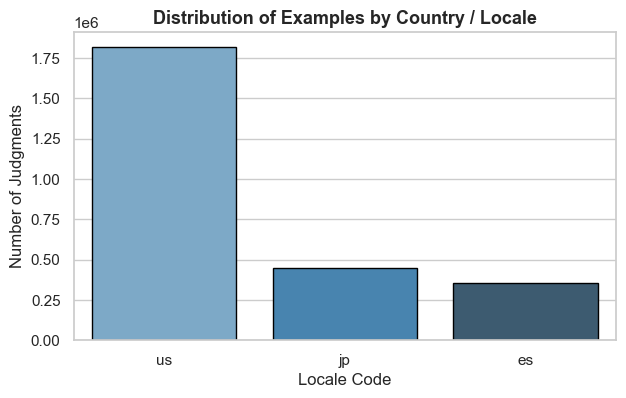

In [3]:
df_examples = pd.read_parquet(ex_path, columns=['query_id', 'query', 'product_id', 'product_locale', 'esci_label', 'small_version', 'split'])

locale_counts = df_examples['product_locale'].value_counts()
locale_pcts = df_examples['product_locale'].value_counts(normalize=True) * 100

locale_df = pd.DataFrame({'Count': locale_counts, 'Percentage (%)': locale_pcts.round(2)})
print('--- Dataset Breakdown by Language / Locale ---')
print(locale_df)

plt.figure(figsize=(7, 4))
sns.barplot(x=locale_df.index, y=locale_df['Count'], palette='Blues_d', edgecolor='black')
plt.title('Distribution of Examples by Country / Locale', fontsize=13, fontweight='bold')
plt.xlabel('Locale Code')
plt.ylabel('Number of Judgments')
plt.show()

### 3. Extracting the English (US) Task 1 Ranking Benchmark
As specified in the benchmark guidelines, Task 1 focuses on ranking candidate products for queries. The reduced benchmark is indicated by `small_version == 1`. For English retrieval, we filter `product_locale == 'us'`.

In [4]:
df_us = df_examples[(df_examples['product_locale'] == 'us') & (df_examples['small_version'] == 1)].copy()

n_judgments = len(df_us)
n_queries = df_us['query_id'].nunique()
n_products = df_us['product_id'].nunique()

print(f'Total Judgments in Task 1 (English): {n_judgments:,}')
print(f'Total Unique Search Queries:          {n_queries:,}')
print(f'Total Unique Products Referenced:     {n_products:,}')
print(f'Average Candidates per Query (Depth): {n_judgments / n_queries:.2f}')

print('\n--- Train vs Test Split Breakdown ---')
split_counts = df_us['split'].value_counts()
split_pcts = df_us['split'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': split_counts, 'Percentage (%)': split_pcts.round(2)}))

Total Judgments in Task 1 (English): 601,354
Total Unique Search Queries:          29,844
Total Unique Products Referenced:     482,105
Average Candidates per Query (Depth): 20.15

--- Train vs Test Split Breakdown ---
        Count  Percentage (%)
split                        
train  419653           69.78
test   181701           30.22


### 4. ESCI Relevance Label Analysis & Class Imbalance
In e-commerce search, evaluating relevance requires understanding the class distribution of ESCI judgments.

--- ESCI Relevance Label Statistics ---
   Label Name   Count  Percentage (%)
E       Exact  261527           43.49
S  Substitute  211191           35.12
C  Complement   27189            4.52
I  Irrelevant  101447           16.87


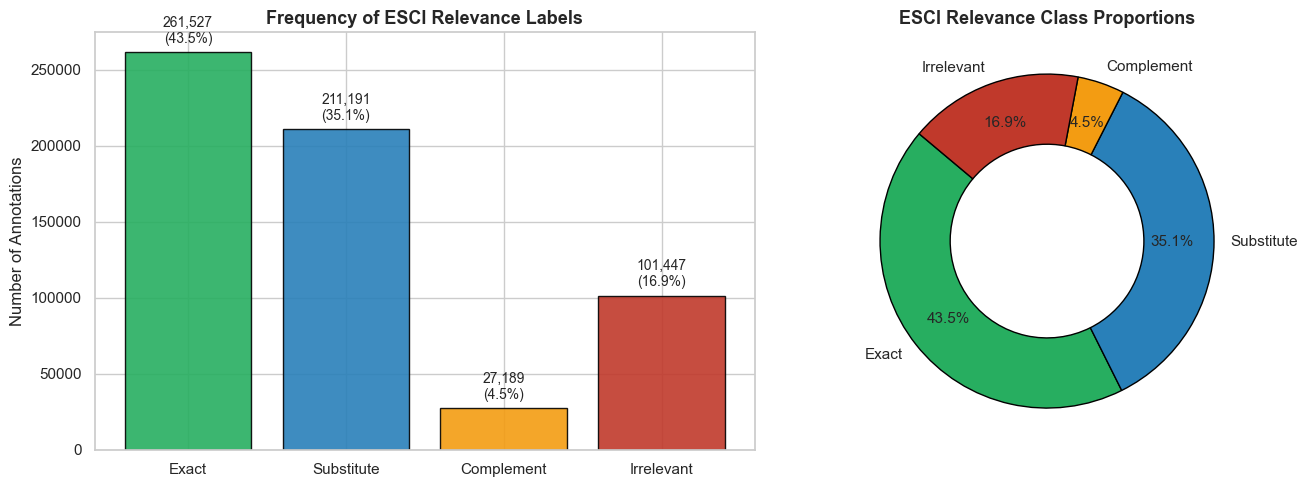

In [5]:
label_order = ['E', 'S', 'C', 'I']
label_counts = df_us['esci_label'].value_counts().reindex(label_order)
label_pcts = df_us['esci_label'].value_counts(normalize=True).reindex(label_order) * 100

esci_summary = pd.DataFrame({
    'Label Name': ['Exact', 'Substitute', 'Complement', 'Irrelevant'],
    'Count': label_counts.values,
    'Percentage (%)': label_pcts.values.round(2)
}, index=label_order)

print('--- ESCI Relevance Label Statistics ---')
print(esci_summary)

# Dual Plot: Bar Chart and Donut Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#27ae60', '#2980b9', '#f39c12', '#c0392b']

# Bar Plot
bars = axes[0].bar(esci_summary['Label Name'], esci_summary['Count'], color=colors, edgecolor='black', alpha=0.9)
axes[0].set_title('Frequency of ESCI Relevance Labels', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Annotations')
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 4000, f'{h:,}\n({h/n_judgments*100:.1f}%)', ha='center', va='bottom', fontsize=10)

# Donut Chart
axes[1].pie(esci_summary['Count'], labels=esci_summary['Label Name'], colors=colors, autopct='%1.1f%%', startangle=140, pctdistance=0.75, wedgeprops=dict(width=0.42, edgecolor='black'))
axes[1].set_title('ESCI Relevance Class Proportions', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### 5. Search Query Characteristics: Word Count & Distribution
Let us inspect the length of real customer queries.

--- Query Length Summary Statistics ---
         word_count    char_count
count  29844.000000  29844.000000
mean       3.888118     22.983347
std        1.827272     10.444763
min        1.000000      1.000000
25%        3.000000     16.000000
50%        4.000000     22.000000
75%        5.000000     28.000000
90%        6.000000     35.000000
95%        7.000000     40.000000
99%        9.000000     53.000000
max       29.000000    171.000000


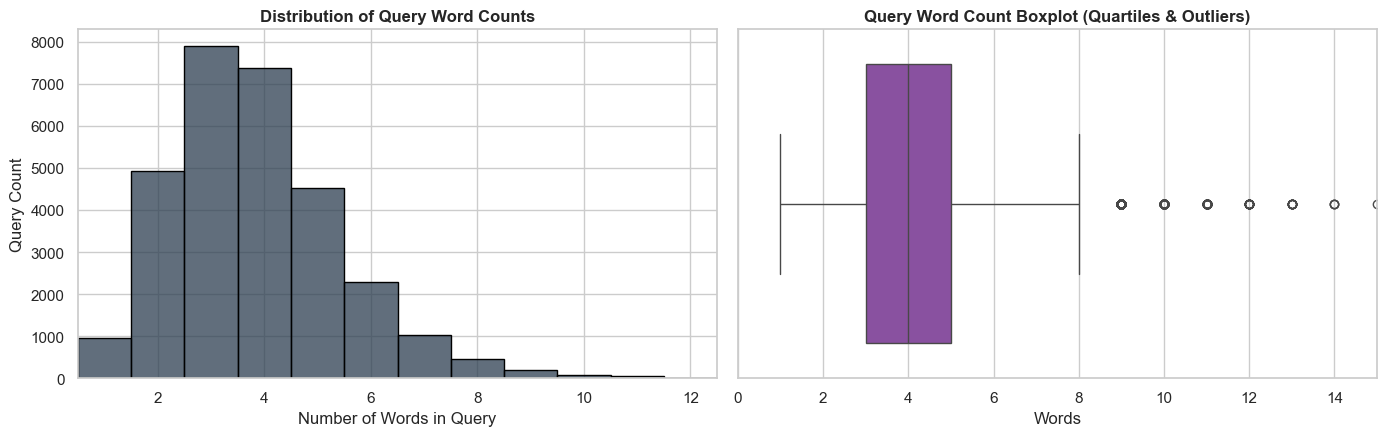

In [6]:
queries_df = df_us[['query_id', 'query']].drop_duplicates().copy()
queries_df['word_count'] = queries_df['query'].astype(str).str.split().str.len()
queries_df['char_count'] = queries_df['query'].astype(str).str.len()

print('--- Query Length Summary Statistics ---')
print(queries_df[['word_count', 'char_count']].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(queries_df['word_count'], bins=range(1, 15), discrete=True, ax=axes[0], color='#2c3e50', edgecolor='black')
axes[0].set_title('Distribution of Query Word Counts', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Words in Query')
axes[0].set_ylabel('Query Count')
axes[0].set_xlim(0.5, 12.5)

sns.boxplot(x=queries_df['word_count'], ax=axes[1], color='#8e44ad')
axes[1].set_title('Query Word Count Boxplot (Quartiles & Outliers)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Words')
axes[1].set_xlim(0, 15)

plt.tight_layout()
plt.show()

### 6. Product Catalog Inspection & Missing Attributes
We now inspect the catalog metadata for all unique products evaluated in Task 1.

Total Matching Products in US Task 1 Catalog: 482,105



--- Product Attributes Missingness ---
                Missing Count  Missing (%)
product_id                  0         0.00
product_title               0         0.00
product_brand           27191         5.64
product_color          155144        32.18
product_locale              0         0.00



--- Product Title Word Count Distribution ---
count    482105.000000
mean         16.740515
std           8.274565
min           1.000000
25%          10.000000
50%          15.000000
75%          23.000000
90%          29.000000
max          80.000000
Name: title_words, dtype: float64


C:\Users\rohit\AppData\Local\Temp\ipykernel_16104\756689196.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.values, y=top_brands.index, palette='crest', edgecolor='black')


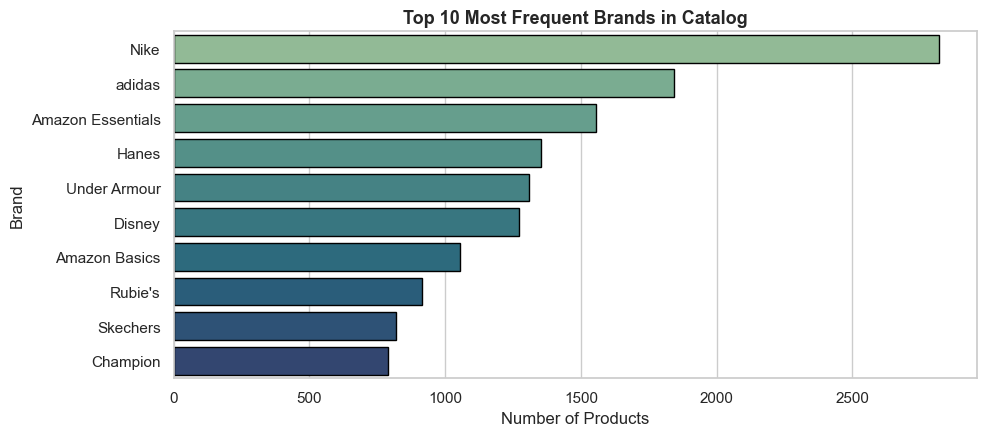

In [7]:
task1_pids = set(df_us['product_id'].unique())

# Load product metadata
df_products = pd.read_parquet(pr_path, columns=['product_id', 'product_title', 'product_brand', 'product_color', 'product_locale'])
df_products_us = df_products[(df_products['product_locale'] == 'us') & (df_products['product_id'].isin(task1_pids))].drop_duplicates(subset=['product_id']).copy()

print(f'Total Matching Products in US Task 1 Catalog: {len(df_products_us):,}')

missing_stats = pd.DataFrame({
    'Missing Count': df_products_us.isnull().sum(),
    'Missing (%)': (df_products_us.isnull().mean() * 100).round(2)
})
print('\n--- Product Attributes Missingness ---')
print(missing_stats)

# Title word count
df_products_us['title_words'] = df_products_us['product_title'].fillna('').str.split().str.len()
print('\n--- Product Title Word Count Distribution ---')
print(df_products_us['title_words'].describe(percentiles=[0.25, 0.50, 0.75, 0.90]))

# Top Brands
top_brands = df_products_us['product_brand'].dropna().value_counts().head(10)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=top_brands.values, y=top_brands.index, palette='crest', edgecolor='black')
plt.title('Top 10 Most Frequent Brands in Catalog', fontsize=13, fontweight='bold')
plt.xlabel('Number of Products')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

### 7. Preparing Working Subsets for Fast Model Iteration
To enable fast iteration during development while keeping full evaluation integrity, we join the test queries with their candidate product titles and export a curated evaluation benchmark.

In [8]:
# Join candidate products with product titles
df_merged = df_us.merge(
    df_products_us[['product_id', 'product_title', 'product_brand']],
    on='product_id',
    how='inner'
)

print(f'Merged Task 1 English Judgments with Titles: {len(df_merged):,} rows')

# Select a representative stratified sample of 1,000 test queries for rapid benchmarking
test_query_ids = df_merged[df_merged['split'] == 'test']['query_id'].unique()
np.random.seed(42)
sample_test_qids = np.random.choice(test_query_ids, size=min(1000, len(test_query_ids)), replace=False)

benchmark_df = df_merged[df_merged['query_id'].isin(sample_test_qids)].copy()

os.makedirs('data', exist_ok=True)
benchmark_path = os.path.join('data', 'benchmark_sample.parquet')
benchmark_df.to_parquet(benchmark_path, index=False)

print(f'Exported benchmark sample to {benchmark_path} ({len(benchmark_df):,} judgments across {len(sample_test_qids)} test queries)')

Merged Task 1 English Judgments with Titles: 601,354 rows


Exported benchmark sample to data\benchmark_sample.parquet (20,156 judgments across 1000 test queries)


### 8. Summary of Findings & Next Steps for IR Pipeline
1. **ESCI Imbalance**: Exact (43.5%) and Substitute (35.1%) make up the vast majority (~78.6%) of relevant judgments. Irrelevant is ~16.9%, while Complement is ~4.5%.
2. **Metric Selection**: Because of graded relevance, **nDCG (Normalized Discounted Cumulative Gain)** is our primary metric, reflecting that an Exact item ranked #1 is better than a Substitute ranked #1.
3. **Lexical vs Dense Retrieval**: Queries are concise (median 3 words), making tokenization, stop-word removal, and Porter stemming critical for sparse models (TF-IDF & BM25), while dense sentence embeddings bridge the semantic gap.
4. **Catalog Integrity**: Over 99.9% of items possess detailed titles (average ~15 words), providing rich lexical and semantic signal for our search index.